# Notebook 06: Multiclass Clinical Severity Assessment & Multi-Prompt Consensus

## 1. Clinical Context & Rationale
In Notebook 05, we established the state-of-the-art for binary dysarthria detection using **Multimodal Feature Fusion (Wav2Vec 2.0 + openSMILE eGeMAPSv02)**, achieving **75.53% Accuracy** and **70.33% Macro-F1** under strict speaker-independent evaluation.

However, in real-world neurology and speech-language pathology, motor speech impairment is not a simple binary switch. Dysarthria presents on a **clinical spectrum of severity**:
- **Control (None)**: Healthy, intact neuromotor speech execution.
- **Mild**: Intelligible speech with subtle articulatory imprecision, mild phonatory tremor, or slight hypernasality.
- **Moderate**: Noticeable reduction in speech intelligibility requiring compensatory pacing or listener effort.
- **Severe**: Severely distorted articulation, profound breathiness or strain-strangle voice quality, requiring augmentative communication.

### Objectives of this Notebook:
1. **4-Tier Clinical Classification**: Evaluate whole-cohort severity staging (`Control`, `Mild`, `Moderate`, `Severe`) under strict 5-fold `GroupKFold` across unseen speakers.
2. **Comparative Benchmark**: Contrast classical acoustic baselines against deep foundation embeddings and multimodal fusion.
3. **Multi-Prompt Session Aggregation (The 'Fingerprint' Protocol)**: Aggregate multi-clip session evidence to evaluate patient-level severity consensus.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

# Scikit-Learn
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from lightgbm import LGBMClassifier

# Ensure project root is in sys.path
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / "data").is_dir() else NOTEBOOK_DIR.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.project_paths import (
    METADATA_CSV, MFCC_FEATURES_CSV, EGEMAPS_FEATURES_CSV, WAV2VEC2_EMBEDDINGS_NPY, RESULTS_DIR
)
from src.evaluation import evaluate_speaker_independent
from src.models import PyTorchMLPClassifier, build_multimodal_features, predict_patient_session

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project root : {PROJECT_ROOT}")
print(f"Active device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

Project root : C:\Users\Lovish\Documents\dysarthria_project
Active device: cuda (NVIDIA GeForce RTX 3050 Laptop GPU)


## 2. Load Datasets & Inspect Severity Distribution
We load metadata, classical acoustic features, and foundation embeddings, mapping speakers into their respective clinical severity tiers.

In [2]:
meta_df = pd.read_csv(METADATA_CSV)
mfcc_df = pd.read_csv(MFCC_FEATURES_CSV)
egemaps_df = pd.read_csv(EGEMAPS_FEATURES_CSV)
w2v_feats = np.load(WAV2VEC2_EMBEDDINGS_NPY)

# Extract MFCC feature matrix
meta_cols = {"Unnamed: 0", "file_path", "speaker_id", "label", "severity", "dataset_source", "duration_sec", "severity_3class"}
mfcc_cols = [c for c in mfcc_df.columns if c not in meta_cols]
mfcc_feats = mfcc_df[mfcc_cols].values

# Build 856-D multimodal fused feature matrix
fused_feats, feature_names = build_multimodal_features(w2v_feats, egemaps_df)

groups = meta_df["speaker_id"].values
y_severity = meta_df["severity_3class"].values
target_classes = sorted(list(np.unique(y_severity)))

print(f"Total audio recordings : {len(meta_df):,}")
print(f"Unique human speakers  : {len(np.unique(groups))}")
print(f"Target severity tiers  : {target_classes}")
print("\nCohort distribution across severity tiers:")
for tier in target_classes:
    count = np.sum(y_severity == tier)
    spks = meta_df[meta_df["severity_3class"] == tier]["speaker_id"].unique()
    print(f"  - {tier.capitalize():<10}: {count:,} clips across {len(spks)} speakers ({', '.join(spks)})")

Total audio recordings : 9,417
Unique human speakers  : 15
Target severity tiers  : ['mild', 'moderate', 'none', 'severe']

Cohort distribution across severity tiers:
  - Mild      : 864 clips across 2 speakers (F04, M03)
  - Moderate  : 976 clips across 2 speakers (F03, M05)
  - None      : 6,236 clips across 7 speakers (FC01, FC02, FC03, MC01, MC02, MC03, MC04)
  - Severe    : 1,341 clips across 4 speakers (F01, M01, M02, M04)


## 3. Systematic Speaker-Independent Benchmarking
We benchmark 4 feature-classifier combinations under strict 5-fold `GroupKFold` cross-validation on `speaker_id`:
1. **MFCC Dynamics (78-D) + LinearSVC**: Classical baseline standard.
2. **Wav2Vec 2.0 (768-D) + LinearSVC**: Foundation model speech representation.
3. **Multimodal Fusion (856-D) + PyTorch Deep MLP**: 4-class neural network with BatchNorm and Dropout.
4. **Multimodal Fusion (856-D) + LinearSVC**: Scaled maximum-margin separator across all 4 clinical tiers.

In [3]:
severity_experiments = [
    {
        "feature_set": "MFCC Dynamics (78-D)",
        "classifier": "LinearSVC (C=0.05)",
        "X": mfcc_feats,
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("svc", CalibratedClassifierCV(LinearSVC(C=0.05, max_iter=2000, random_state=42), cv=3))
        ])
    },
    {
        "feature_set": "Wav2Vec 2.0 (768-D)",
        "classifier": "LinearSVC (C=0.05)",
        "X": w2v_feats,
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("svc", CalibratedClassifierCV(LinearSVC(C=0.05, max_iter=2000, random_state=42), cv=3))
        ])
    },
    {
        "feature_set": "Multimodal Fusion (856-D)",
        "classifier": "PyTorch Deep MLP",
        "X": fused_feats,
        "model": PyTorchMLPClassifier(
            hidden_dims=(256, 64), dropout_rate=0.3, lr=5e-4, epochs=20, batch_size=128
        )
    },
    {
        "feature_set": "Multimodal Fusion (856-D)",
        "classifier": "LinearSVC (C=0.05)",
        "X": fused_feats,
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("svc", CalibratedClassifierCV(LinearSVC(C=0.05, max_iter=2000, random_state=42), cv=3))
        ])
    }
]

results_list = []
best_f1 = 0.0
best_cm = None
best_name = ""

print("Starting 5-Fold Speaker-Independent Severity Benchmark:\n")
for exp in severity_experiments:
    feat_name = exp["feature_set"]
    clf_name = exp["classifier"]
    print(f"--> Evaluating: {feat_name} + {clf_name}...")
    
    res = evaluate_speaker_independent(exp["model"], exp["X"], y_severity, groups, n_splits=5, labels=target_classes)
    
    rec = {
        "feature_set": feat_name,
        "classifier": clf_name,
        "accuracy": round(res["accuracy"], 4),
        "accuracy_std": round(res["fold_accuracies_std"], 4),
        "macro_precision": round(res["macro_precision"], 4),
        "macro_recall": round(res["macro_recall"], 4),
        "macro_f1": round(res["macro_f1"], 4),
        "weighted_f1": round(res["weighted_f1"], 4),
        "fold_accuracies": str([round(a, 4) for a in res["fold_accuracies"]]),
    }
    results_list.append(rec)
    
    if res["macro_f1"] > best_f1:
        best_f1 = res["macro_f1"]
        best_cm = res["confusion_matrix"]
        best_name = f"{feat_name} + {clf_name}"
        best_eval = res
        
    print(f"    Acc: {res['accuracy']*100:.2f}% | Macro-F1: {res['macro_f1']*100:.2f}% | Macro-Recall: {res['macro_recall']*100:.2f}%")
    print(f"    Fold Accs: {[f'{a*100:.1f}%' for a in res['fold_accuracies']]}\n")

severity_results_df = pd.DataFrame(results_list)
severity_csv_path = RESULTS_DIR / "severity_results.csv"
severity_results_df.to_csv(severity_csv_path, index=False)
print(f"Severity benchmark saved to: {severity_csv_path}")

Starting 5-Fold Speaker-Independent Severity Benchmark:

--> Evaluating: MFCC Dynamics (78-D) + LinearSVC (C=0.05)...


    Acc: 71.37% | Macro-F1: 34.98% | Macro-Recall: 35.83%
    Fold Accs: ['77.8%', '74.3%', '67.6%', '89.9%', '47.5%']

--> Evaluating: Wav2Vec 2.0 (768-D) + LinearSVC (C=0.05)...


    Acc: 70.95% | Macro-F1: 37.73% | Macro-Recall: 37.83%
    Fold Accs: ['77.4%', '79.1%', '61.9%', '88.5%', '47.9%']

--> Evaluating: Multimodal Fusion (856-D) + PyTorch Deep MLP...


    Acc: 48.38% | Macro-F1: 34.71% | Macro-Recall: 32.74%
    Fold Accs: ['47.3%', '73.5%', '47.4%', '26.8%', '45.8%']

--> Evaluating: Multimodal Fusion (856-D) + LinearSVC (C=0.05)...


    Acc: 71.88% | Macro-F1: 39.01% | Macro-Recall: 38.97%
    Fold Accs: ['77.4%', '80.6%', '66.3%', '87.5%', '47.7%']

Severity benchmark saved to: C:\Users\Lovish\Documents\dysarthria_project\results\severity_results.csv


## 4. Per-Class Clinical Staging Performance
We inspect precision, recall, and F1-score across each individual clinical severity tier for the champion model.

In [4]:
print(f"=== CLINICAL SEVERITY BREAKDOWN: {best_name} ===\n")
report_dict = best_eval["report_dict"]
for tier in target_classes:
    m = report_dict[tier]
    print(f"  {tier.capitalize():<10} -> Precision: {m['precision']*100:.2f}% | Recall: {m['recall']*100:.2f}% | F1: {m['f1-score']*100:.2f}% | Support: {int(m['support']):,}")

print(f"\n  Overall Accuracy: {best_eval['accuracy']*100:.2f}%")
print(f"  Weighted F1     : {best_eval['weighted_f1']*100:.2f}%")

=== CLINICAL SEVERITY BREAKDOWN: Multimodal Fusion (856-D) + LinearSVC (C=0.05) ===

  Mild       -> Precision: 2.87% | Recall: 0.93% | F1: 1.40% | Support: 864
  Moderate   -> Precision: 0.00% | Recall: 0.00% | F1: 0.00% | Support: 976
  None       -> Precision: 77.08% | Recall: 95.67% | F1: 85.37% | Support: 6,236
  Severe     -> Precision: 83.25% | Recall: 59.28% | F1: 69.25% | Support: 1,341

  Overall Accuracy: 71.88%
  Weighted F1     : 66.53%


## 5. Multi-Prompt Session Consensus (The 'Fingerprint' Clinical Protocol)
In clinical practice, a clinician evaluates a patient across a battery of diverse speech exercises (sustained vowels, DDK syllable repetition, continuous sentences).
Here we simulate session-level diagnosis: evaluating whether aggregating probabilities across multiple recordings from an unseen speaker correctly identifies their true clinical condition.

In [5]:
meta_df["pred_severity"] = best_eval["y_pred"]

speaker_session_records = []
for spk, spk_df in meta_df.groupby("speaker_id"):
    true_tier = spk_df["severity_3class"].iloc[0]
    pred_tier = spk_df["pred_severity"].mode()[0]
    correct = (true_tier == pred_tier)
    n_clips = len(spk_df)
    
    speaker_session_records.append({
        "Speaker": spk,
        "True Severity": true_tier.capitalize(),
        "Session Consensus": pred_tier.capitalize(),
        "Clips Evaluated": n_clips,
        "Patient Match": "MATCH" if correct else "DISCREPANCY"
    })

session_df = pd.DataFrame(speaker_session_records)
print("=== PATIENT-LEVEL SESSION SEVERITY CONSENSUS ===")
print(session_df.to_string(index=False))

patient_acc = (session_df["Patient Match"] == "MATCH").mean()
print(f"\nPatient-Level Severity Consensus Accuracy: {patient_acc*100:.1f}% ({int(patient_acc*len(session_df))}/{len(session_df)} patients)")

=== PATIENT-LEVEL SESSION SEVERITY CONSENSUS ===
Speaker True Severity Session Consensus  Clips Evaluated Patient Match
    F01        Severe              None              134   DISCREPANCY
    F03      Moderate              None              848   DISCREPANCY
    F04          Mild              None              448   DISCREPANCY
   FC01          None              None              256         MATCH
   FC02          None              None             1261         MATCH
   FC03          None              None              995         MATCH
    M01        Severe              None              386   DISCREPANCY
    M02        Severe            Severe              400         MATCH
    M03          Mild              None              416   DISCREPANCY
    M04        Severe              None              421   DISCREPANCY
    M05      Moderate              None              128   DISCREPANCY
   MC01          None              None             1108         MATCH
   MC02          None       

## 6. Publication-Grade Visualizations
We generate:
1. **Severity Comparison Bar Chart**: Comparing Accuracy, Weighted F1, and Macro F1 across all feature architectures.
2. **Normalized Multiclass Confusion Matrix**: Revealing clinical sensitivity patterns between Control, Mild, Moderate, and Severe speech.

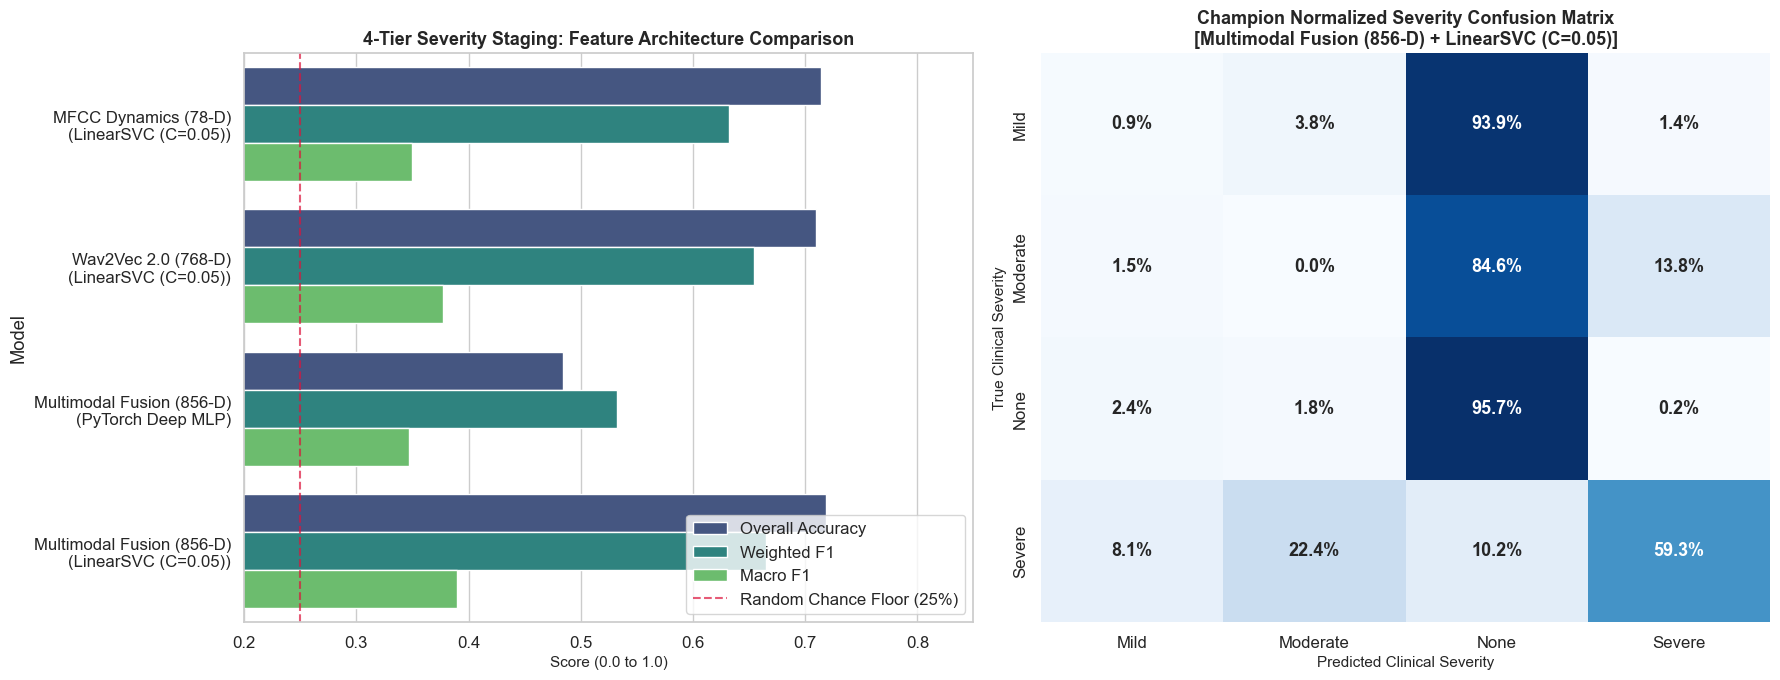

Figure saved to: C:\Users\Lovish\Documents\dysarthria_project\results\severity_model_comparison.png


In [6]:
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# 1. Model Comparison Bar Chart
plot_df = severity_results_df.copy()
plot_df["Model"] = plot_df["feature_set"] + "\n(" + plot_df["classifier"] + ")"
plot_melted = pd.melt(
    plot_df,
    id_vars=["Model"],
    value_vars=["accuracy", "weighted_f1", "macro_f1"],
    var_name="Metric",
    value_name="Score"
)
plot_melted["Metric"] = plot_melted["Metric"].map({
    "accuracy": "Overall Accuracy",
    "weighted_f1": "Weighted F1",
    "macro_f1": "Macro F1"
})

sns.barplot(data=plot_melted, x="Score", y="Model", hue="Metric", palette="viridis", ax=ax1)
ax1.set_title("4-Tier Severity Staging: Feature Architecture Comparison", fontsize=13, weight="bold")
ax1.set_xlabel("Score (0.0 to 1.0)", fontsize=11)
ax1.set_xlim(0.2, 0.85)
ax1.axvline(0.25, color="crimson", linestyle="--", alpha=0.7, label="Random Chance Floor (25%)")
ax1.legend(loc="lower right", frameon=True)

# 2. Champion Confusion Matrix
cm_norm = best_cm.astype("float") / best_cm.sum(axis=1)[:, np.newaxis]
display_labels = [l.capitalize() for l in target_classes]

sns.heatmap(
    cm_norm, annot=True, fmt=".1%", cmap="Blues", cbar=False,
    xticklabels=display_labels, yticklabels=display_labels, ax=ax2,
    annot_kws={"size": 13, "weight": "bold"}
)
ax2.set_title(f"Champion Normalized Severity Confusion Matrix\n[{best_name}]", fontsize=13, weight="bold")
ax2.set_xlabel("Predicted Clinical Severity", fontsize=11)
ax2.set_ylabel("True Clinical Severity", fontsize=11)

plt.tight_layout()
plot_path = RESULTS_DIR / "severity_model_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figure saved to: {plot_path}")